# <span style="color: green"><strong> *Data for Paper*<strong></span>

# <span style="color:orange"> *Single Probe Case*</span>

### <span style="color:green"><strong> *Libraries*<strong></span>

In [14]:
import numpy as np
import pandas as pd
import os 
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import BoundaryNorm

### <span style="color:green"><strong>*Parameters*<strong></span>

In [15]:
d_values = np.arange(1,21)   # Hilbert-space dimension

M_values = np.arange(1,41)   # number of channel applications

D, M = np.meshgrid(d_values, M_values)

p_values = [0.001,0.01]                     # small depolarizing parameter

In [16]:
# Dictionary to store RQFI for each p
RQFI_data = {}

### <span style="color:green"><strong>*Regularized Quantum Fisher Information*<strong></span>

In [17]:
# ==========================================================
# Regularized Quantum Fisher Information
# ==========================================================

for p in p_values:

    s = 1 - D * p

    RQFI = (
        p
        * D**2
        * (D - 1)
        * M**2
        * s**(2*M - 2)
    ) / (
        (1 + (D - 1) * s**M)
        *
        (1 - s**M)
    )

    # Save RQFI corresponding to this p
    RQFI_data[p] = RQFI

## <span style="color:orange"><strong> *Figure 1* <strong></span>

### <span style="color:green"><strong> *Plotting Figure 1(a) <strong>*</span>

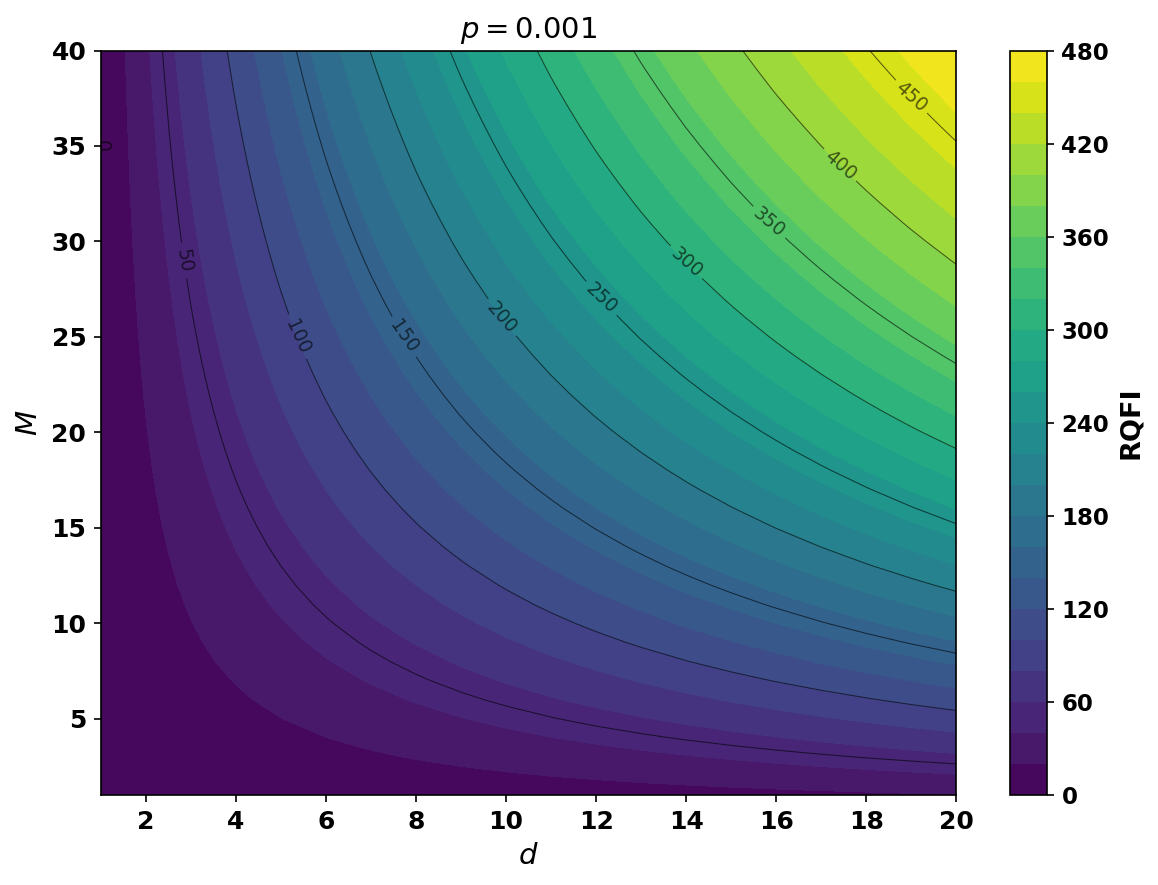

In [18]:
# ==========================================================
# Plot
# ==========================================================

p_plot = 0.001

RQFI = RQFI_data[p_plot]

plt.figure(figsize=(8, 6), dpi=150)

# Filled contour + contour lines
contour = plt.contourf(D, M, RQFI, levels=25, cmap='viridis')

lines = plt.contour(
    D, M, RQFI,
    levels=10,
    colors='black',
    linewidths=0.5,
    alpha=0.6
)

plt.clabel(lines, fontsize=9, fmt='%.0f')

# Colorbar
cbar = plt.colorbar(contour)
cbar.set_label('RQFI', fontsize=13, fontweight='bold')
cbar.ax.tick_params(labelsize=11)
plt.setp(cbar.ax.get_yticklabels(), fontweight='bold')

# Axes formatting
plt.xlabel('$d$', fontsize=14, fontweight='bold')
plt.ylabel('$M$', fontsize=14, fontweight='bold')

plt.xticks(np.arange(2, 21, 2), fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.title(fr'$p={p_plot}$', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### <span style="color:green"><strong> *Plotting Figure 1(b)* <strong></span>

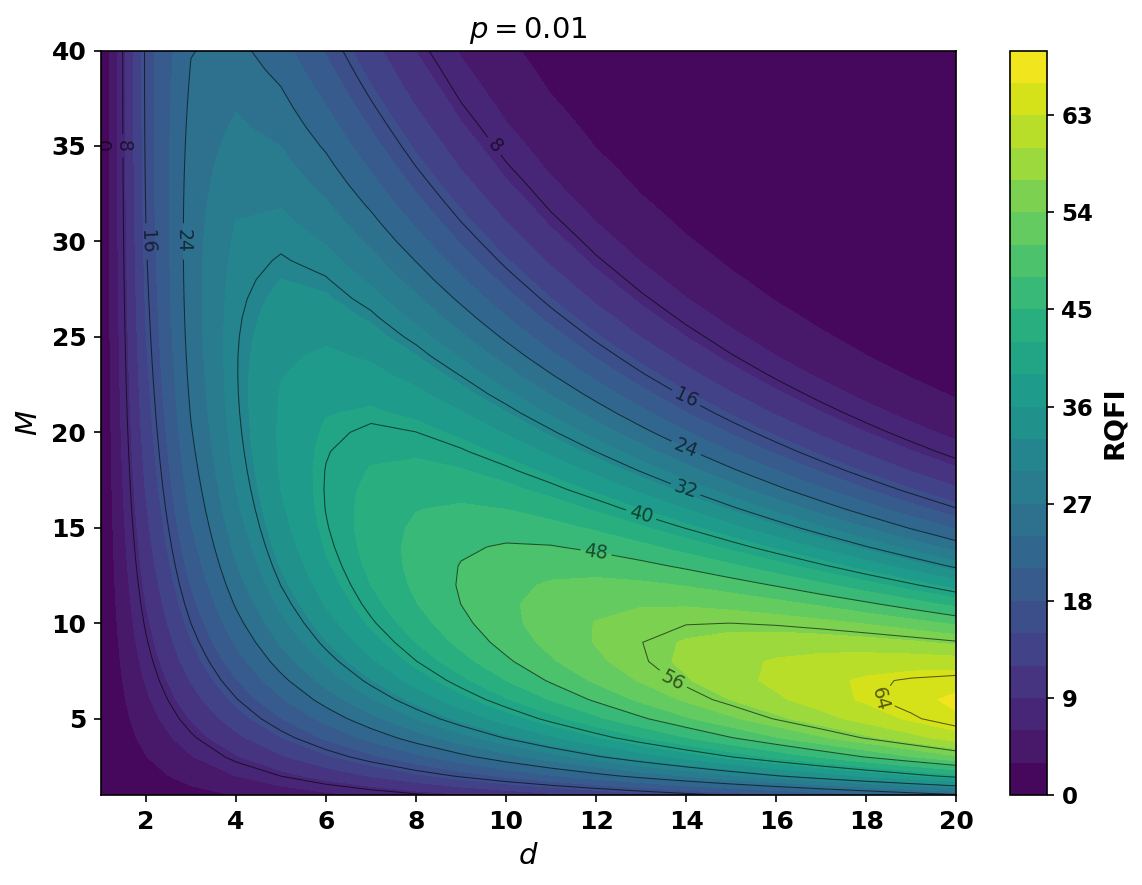

In [19]:
# ==========================================================
# Plot
# ==========================================================

p_plot = 0.01

RQFI = RQFI_data[p_plot]

plt.figure(figsize=(8, 6), dpi=150)

# Filled contour + contour lines
contour = plt.contourf(D, M, RQFI, levels=25, cmap='viridis')

lines = plt.contour(
    D, M, RQFI,
    levels=10,
    colors='black',
    linewidths=0.5,
    alpha=0.6
)

plt.clabel(lines, fontsize=9, fmt='%.0f')

# Colorbar
cbar = plt.colorbar(contour)
cbar.set_label('RQFI', fontsize=13, fontweight='bold')
cbar.ax.tick_params(labelsize=11)
plt.setp(cbar.ax.get_yticklabels(), fontweight='bold')

# Axes formatting
plt.xlabel('$d$', fontsize=14, fontweight='bold')
plt.ylabel('$M$', fontsize=14, fontweight='bold')

plt.xticks(np.arange(2, 21, 2), fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.title(fr'$p={p_plot}$', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## <span style="color:orange"><strong> *Figure 2* <strong></span>

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [20]:
# ==========================================================
# Analytical QFI
# ==========================================================

def qfi_single_probe(d, p, M):

    s = 1 - d*p

    # Outside the physical region
    if s <= 0:
        return np.nan

    numerator = (
        d**2
        * (d-1)
        * M**2
        * s**(2*M-2)
    )

    denominator = (
        (1 + (d-1)*s**M)
        *
        (1 - s**M)
    )

    return numerator / denominator

### <span style="color:green"><strong> *Parameters* <strong></span>

In [21]:
# ==========================================================
# Parameters
# ==========================================================

d_values = [2, 3, 4, 5]

pd_values = np.linspace(0.001, 0.22, 200)

M_scan = np.arange(1, 101)

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:red'
]


### <span style="color:green"><strong> *Plotting* <strong></span>

d = 2: M* = 0.3312 p^(-1.0387), R^2 = 0.98906
d = 3: M* = 0.2310 p^(-1.0520), R^2 = 0.98961
d = 4: M* = 0.1809 p^(-1.0545), R^2 = 0.98954
d = 5: M* = 0.1439 p^(-1.0663), R^2 = 0.99020


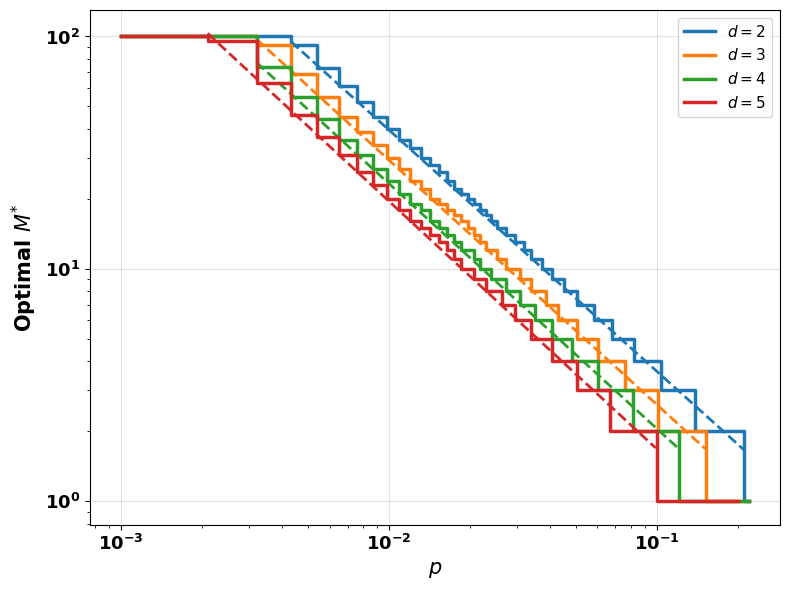

In [22]:
# ==========================================================
# Plot
# ==========================================================

plt.figure(figsize=(8,6))

for d, color in zip(d_values, colors):

    best_M = []

    for p in pd_values:

        # Physical region
        if p >= 1/d:
            best_M.append(np.nan)
            continue

        qfi_values = []

        for M in M_scan:

            qfi_values.append(
                qfi_single_probe(d, p, M)
            )

        qfi_values = np.array(qfi_values)

        M_opt = M_scan[np.argmax(qfi_values)]

        best_M.append(M_opt)


    # Convert to NumPy array for fitting
    best_M = np.array(best_M, dtype=float)


    # ======================================================
    # Numerical optimal M
    # ======================================================

    plt.step(
        pd_values,
        best_M,
        where='post',
        linewidth=2.5,
        color=color,
        label=rf'$d={d}$'
    )


    # ======================================================
    # Linear fit in log-log coordinates
    #
    # log(M*) = alpha log(p) + log(A)
    #
    # Equivalent to:
    #
    # M* = A p^alpha
    # ======================================================

    fit_mask = (
        np.isfinite(best_M)
        & (best_M > 1)
        & (best_M < M_scan.max())
    )

    p_fit = pd_values[fit_mask]
    M_fit = best_M[fit_mask]


    # Linear regression in log-log space
    coefficients = np.polyfit(
        np.log10(p_fit),
        np.log10(M_fit),
        1
    )

    alpha = coefficients[0]
    log_A = coefficients[1]

    A = 10**log_A


    # Fitted values
    M_fit_line = A * p_fit**alpha


    # ======================================================
    # R^2 in log-log space
    # ======================================================

    log_M_data = np.log10(M_fit)
    log_M_pred = np.log10(M_fit_line)

    SS_res = np.sum(
        (log_M_data - log_M_pred)**2
    )

    SS_tot = np.sum(
        (log_M_data - np.mean(log_M_data))**2
    )

    R_squared = 1 - SS_res / SS_tot


    # ======================================================
    # Plot fitted line
    # ======================================================

    plt.plot(
        p_fit,
        M_fit_line,
        '--',
        color=color,
        linewidth=2
    )


    # Print fitting parameters
    print(
        f"d = {d}: "
        f"M* = {A:.4f} p^({alpha:.4f}), "
        f"R^2 = {R_squared:.5f}"
    )


# ==========================================================
# Formatting
# ==========================================================

plt.xlabel(
    r'$p$',
    fontsize=15,
    fontweight='bold'
)

plt.ylabel(
    r'Optimal $M^{*}$',
    fontsize=15,
    fontweight='bold'
)

plt.xticks(
    fontsize=13,
    fontweight='bold'
)

plt.yticks(
    fontsize=13,
    fontweight='bold'
)


# ==========================================================
# Log-log scale
# ==========================================================

plt.yscale('log')
plt.xscale('log')


plt.grid(
    alpha=0.35
)


plt.legend(
    prop={
        'weight':'bold',
        'size':11
    }
)


plt.tight_layout()

plt.show()

## <span style="color:orange"><strong> *Figure 3* <strong></span>

### <span style="color:green"><strong> *Main Plot - QFI* <strong></span>

### <span style="color:green"><strong> *Initial state* <strong></span>

In [23]:
# -----------------------------
# Initial state: |0><0|
# -----------------------------
ket0 = np.array([[1.0], [0.0]], dtype=complex)
rho0 = ket0 @ ket0.conj().T

# Identity matrix
I2 = np.eye(2, dtype=complex)
I4 = np.eye(4, dtype=complex)

### <span style="color:green"><strong> *Output state after M applications* <strong></span>

In [24]:
def rho_out(p, M, rho_init):
    a = (1 - 2*p)**M
    return a * rho_init + (1 - a) * I2 / 2

### <span style="color:green"><strong> *Derivative $d\rho_p/dp$* <strong></span>

In [25]:
def drho_dp(p, M, rho_init):
    da_dp = -2 * M * (1 - 2*p)**(M - 1)
    return da_dp * (rho_init - I2 / 2)

### <span style="color:green"><strong> *SLD-based numerical QFI* <strong></span>

In [26]:
def qfi_sld(rho, drho, tol=1e-12):
    eigvals, eigvecs = np.linalg.eigh(rho)
    L = np.zeros_like(rho, dtype=complex)

    for i in range(len(eigvals)):
        for j in range(len(eigvals)):
            denom = eigvals[i] + eigvals[j]
            if denom > tol:
                vi = eigvecs[:, i]
                vj = eigvecs[:, j]
                drho_ij = np.vdot(vi, drho @ vj)
                L += (2 * drho_ij / denom) * np.outer(vi, np.conj(vj))

    qfi = np.real(np.trace(drho @ L))
    return qfi

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [27]:
def qfi_analytical(p, M):
    numerator = 4 * M**2 * (1 - 2*p)**(2*M - 2)
    denominator = 1 - (1 - 2*p)**(2*M)
    return numerator / denominator

### <span style="color:green"><strong> *Parameters* <strong></span>

In [28]:
p_vals = np.linspace(0.01, 0.1, 100)
M_list = [1, 2, 3, 5, 10]

handles=[]

### <span style="color:green"><strong> *Plotting* <strong></span>

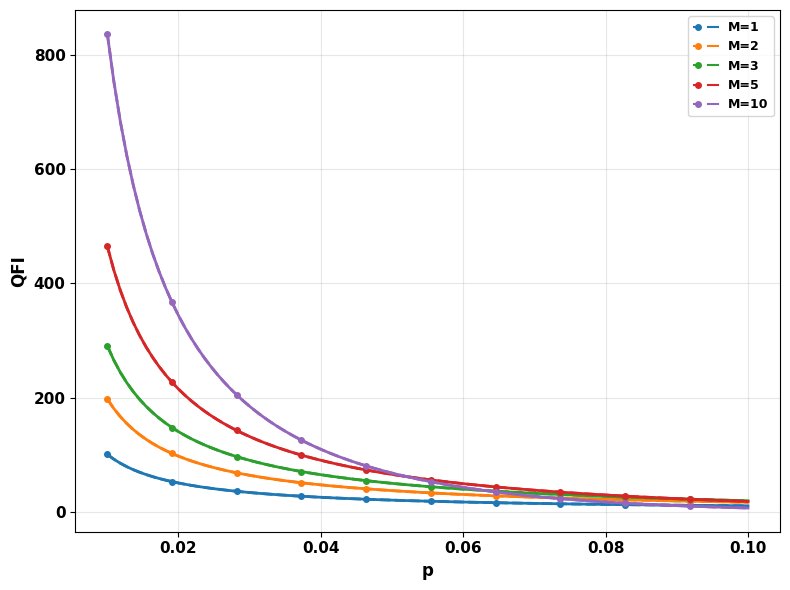

In [ ]:
plt.figure(figsize=(8, 6))

for M in M_list:
    # Numerical
    qfi_num_vals = []
    for p in p_vals:
        rho_p = rho_out(p, M, rho0)
        drho_p = drho_dp(p, M, rho0)
        qfi_num_vals.append(qfi_sld(rho_p, drho_p))

    # Analytical
    qfi_ana_vals = qfi_analytical(p_vals, M)

    # Plot numerical: solid line
    line = plt.plot(p_vals, qfi_num_vals, linestyle='--', marker='o', markevery=10, markersize=4, linewidth=2)
    
    # Use of same color for analytical of same M
    color = line[0].get_color()

    # Plot analytical: dashed + markers
    plt.plot(
        p_vals,
        qfi_ana_vals,
        #linestyle='--',
        #marker='o',
        #markevery=20,
        #markersize=4,
        color=color,
        linewidth=2,
     )
    handles.append(
        (
            Line2D([], [], color=color, linestyle='--',
                   marker='o', markersize=4),
            Line2D([], [], color=color, linestyle='-')
        )
    )
labels=[f"M={M}" for M in M_list]    

plt.xlabel("p", fontsize=12, fontweight='bold')
plt.xticks(fontsize=11, fontweight='bold')
plt.ylabel("QFI", fontsize=12, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
plt.legend(handles, labels, handler_map={tuple: plt.matplotlib.legend_handler.HandlerTuple(ndivide=None)},prop={'weight':'bold','size':9})
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### <span style="color:green"><strong> *Inset Regularized QFI* <strong></span>

### <span style="color:green"><strong> *Parameters* <strong></span>

In [30]:
p_vals_RQFI = np.linspace(0.01, 0.5, 100)
handles_RQFI = []

### <span style="color:green"><strong> *Plotting* <strong></span>

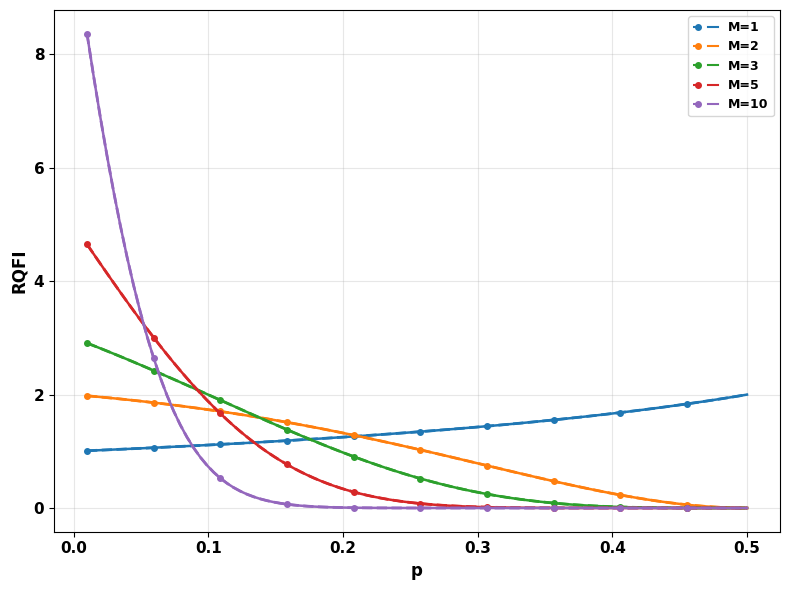

In [ ]:
plt.figure(figsize=(8, 6))

for M in M_list:
    # Numerical
    qfi_num_vals = []
    for p in p_vals_RQFI:
        rho_p = rho_out(p, M, rho0)
        drho_p = drho_dp(p, M, rho0)
        qfi_num_vals.append(p * qfi_sld(rho_p, drho_p))

    # Analytical
    qfi_ana_vals = p_vals_RQFI * qfi_analytical(p_vals_RQFI, M)

    # Plot numerical: solid line
    line = plt.plot(p_vals_RQFI, qfi_num_vals, linestyle='--', marker='o', markevery=10, markersize=4, linewidth=2)
    
    # Use of same color for analytical of same M
    color = line[0].get_color()

    # Plot analytical: dashed + markers
    plt.plot(
        p_vals_RQFI,
        qfi_ana_vals,
        #linestyle='--',
        color=color,
        linewidth=1.8,
        )
    handles_RQFI.append(
        (
            Line2D([], [], color=color, linestyle='--',
                   marker='o', markersize=4),
            Line2D([], [], color=color, linestyle='-')
        )
    )
labels=[f"M={M}" for M in M_list]

plt.xlabel("p", fontsize=12, fontweight='bold')
plt.xticks(fontsize=11, fontweight='bold')
plt.ylabel(r"RQFI", fontsize=12, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
plt.legend(handles_RQFI, labels, handler_map={tuple: plt.matplotlib.legend_handler.HandlerTuple(ndivide=None)},prop={'weight':'bold','size':9})
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## <span style="color:orange"><strong> *Figure 4-Purity* <strong></span>

### <span style="color:green"><strong> *Parameters* <strong></span>

In [32]:
# -----------------------------
# Fixed populations
# rho0 = [[P1, f],
#         [f*, P2]]
# -----------------------------
P1 = 0.5
P2 = 0.5

# Fixed depolarizing parameter
p_fixed = 0.05

# Allowed range: |f| <= sqrt(P1*P2)
f_abs_vals = np.linspace(0.0, np.sqrt(P1 * P2) - 1e-10, 100)

### <span style="color:green"><strong> *Function to construct generic state* <strong></span>

In [33]:
def construct_rho0(f_abs):
    f = f_abs

    # Numerical tolerance for P1*P2 >= |f|^2
    if np.abs(f)**2 - P1 * P2 > 1e-12:
        raise ValueError("Condition violated: P1*P2 must be >= |f|^2")

    rho0 = np.array([
        [P1, f],
        [np.conj(f), P2]
    ], dtype=complex)

    eigvals = np.linalg.eigvalsh(rho0)

    if np.any(eigvals < -1e-12):
        raise ValueError("Condition violated: rho must be positive semidefinite")

    return rho0

### <span style="color:green"><strong> *Purity* <strong></span>

In [34]:
def purity_state(P1, P2, f_abs):
    return P1**2 + P2**2 + 2 * f_abs**2

### <span style="color:green"><strong> *Output State* <strong></span>

In [35]:
def rho_out(p, M, rho_init):
    aM = (1 - 2*p)**M
    return aM * rho_init + (1 - aM) * I2 / 2

### <span style="color:green"><strong> *Derivative* <strong></span>

In [36]:
def drho_dp(p, M, rho_init):
    daM_dp = -2 * M * (1 - 2*p)**(M - 1)
    return daM_dp * (rho_init - I2 / 2)

### <span style="color:green"><strong> *Numerical QFI* <strong></span>

In [37]:
def qfi_sld(rho, drho, tol=1e-12):
    eigvals, eigvecs = np.linalg.eigh(rho)
    L = np.zeros_like(rho, dtype=complex)

    for i in range(len(eigvals)):
        for j in range(len(eigvals)):
            denom = eigvals[i] + eigvals[j]
            if denom > tol:
                vi = eigvecs[:, i]
                vj = eigvecs[:, j]
                drho_ij = np.vdot(vi, drho @ vj)
                L += (2 * drho_ij / denom) * np.outer(vi, np.conj(vj))

    qfi = np.real(np.trace(drho @ L))
    return qfi

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [38]:
def bloch_norm_sq(rho_init):
    P1_local = np.real(rho_init[0, 0])
    P2_local = np.real(rho_init[1, 1])
    f_local = rho_init[0, 1]
    return (P1_local - P2_local)**2 + 4 * np.abs(f_local)**2

def qfi_analytical_generic(p, M, rho_init):
    r2 = bloch_norm_sq(rho_init)
    numerator = 4 * M**2 * (1 - 2*p)**(2*M - 2) * r2
    denominator = 1 - r2 * (1 - 2*p)**(2*M)
    return numerator / denominator

In [39]:
handles_QFIP=[]

### <span style="color:green"><strong> *Plotting* <strong></span>

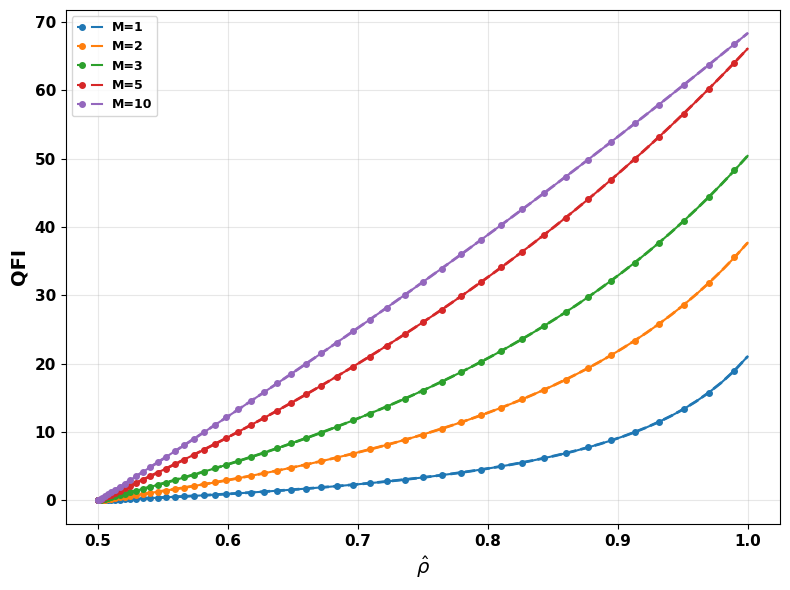

In [41]:
plt.figure(figsize=(8, 6))

for M in M_list:
    purity_vals = []
    qfi_num_vals = []
    qfi_ana_vals = []

    for f_abs in f_abs_vals:
        rho0 = construct_rho0(f_abs)

        rho_p = rho_out(p_fixed, M, rho0)
        drho_p = drho_dp(p_fixed, M, rho0)

        purity_vals.append(purity_state(P1, P2, f_abs))
        qfi_num_vals.append(qfi_sld(rho_p, drho_p))
        qfi_ana_vals.append(qfi_analytical_generic(p_fixed, M, rho0))

    line = plt.plot(
        purity_vals,
        qfi_num_vals,
        linestyle='--',marker='o', markevery=2, markersize=4,
        linewidth=2
    )

    color = line[0].get_color()

    plt.plot(
        purity_vals,
        qfi_ana_vals,
        color=color,
        )
    handles_QFIP.append(
        (
            Line2D([], [], color=color, linestyle='--',
                   marker='o', markersize=4),
            Line2D([], [], color=color, linestyle='-')
        )
    )
labels = [f"M={M}" for M in M_list]

plt.xlabel(r"$\hat{\rho}$", fontsize=14, fontweight='bold')
plt.ylabel("QFI", fontsize=14, fontweight='bold')
#plt.title(r"QFI vs purity for a generic qubit state", fontsize=13, fontweight='bold')
plt.legend(
    handles_QFIP,
    labels,
    handler_map={tuple: plt.matplotlib.legend_handler.HandlerTuple(ndivide=None)},
    prop={'weight':'bold','size':9}
)
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("QFI vs purity.pdf", bbox_inches="tight")
plt.show()

# <span style="color:orange"><strong> *Two Probe Case* <strong></span>

### <span style="color:green"><strong> *Figure 5(a,b,c,d)* <strong></span>

### <span style="color:green"><strong> *Partial Traces* <strong></span>

In [32]:
def partial_trace_1(rho):
    rr = rho.reshape(2, 2, 2, 2)
    return np.array([[sum(rr[i,a,i,b] for i in range(2)) for b in range(2)] for a in range(2)], dtype=complex)

def partial_trace_2(rho):
    rr = rho.reshape(2, 2, 2, 2)
    return np.array([[sum(rr[a,i,b,i] for i in range(2)) for b in range(2)] for a in range(2)], dtype=complex)

def make_S(rho):
    return np.kron(I2, partial_trace_1(rho)) + np.kron(partial_trace_2(rho), I2)

### <span style="color:green"><strong> *Depolarizing Channel for Generic M* <strong></span>

In [33]:
def depolarizing_generic(rho, p, M):
    s = (1 - 2*p)
    A = s**(2*M)
    B = ((s**M - s**(2*M))/2)
    C = (1 - 2*(s**M) + s**(2*M))/4
    S = make_S(rho)
    out = A*rho + B*S + C*I4
    return 0.5*(out + out.conj().T)

### <span style="color:green"><strong> *Analytical derivative* <strong></span>

In [34]:
def d_Lambda_deps_generic(p, rho_init, S_init, M):
    s = (1 - 2*p)
    alpha = -4*M*(s**(2*M-1))
    beta  = M*(s**(M-1))*(2*(s**M)-1)
    gamma = M*(s**(M-1))*(1 - (s**M))
    return alpha*rho_init + beta*S_init + gamma*I4

### <span style="color:green"><strong> *Initial state* <strong></span>

In [37]:
def create_initial_state(mu):
    psi = np.array([np.sqrt(mu), 0, 0, np.sqrt(1 - mu)], dtype=complex)
    return np.outer(psi, psi.conj())

### <span style="color:green"><strong> *Numerical QFI* <strong></span>

In [38]:
def compute_qfi_numerical(rho_out, drho):
    rho_out = 0.5*(rho_out + rho_out.conj().T)
    drho    = 0.5*(drho + drho.conj().T)
    eigvals, eigvecs = np.linalg.eigh(rho_out)
    eigvals = np.maximum(eigvals, 1e-12)
    drho_eig = eigvecs.conj().T @ drho @ eigvecs
    L = np.zeros((4,4), dtype=complex)
    for i in range(4):
        for j in range(4):
            denom = eigvals[i] + eigvals[j]
            if denom > 1e-12:
                L[i,j] = 2*drho_eig[i,j] / denom
    qfi = sum(eigvals[i]*abs(L[i,j])**2 for i in range(4) for j in range(4))
    return float(np.real(qfi))

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [39]:
def compute_qfi_analytical_generic(mu, p, M):
    s = (1 - 2*p)
    r = np.sqrt(mu*(1-mu))
    A = s**(2*M)
    B = (s**M - s**(2*M))/2
    C = (1 - 2*(s**M) + s**(2*M))/4
    lB = B + C
    m00 = mu*(A + 2*B) + C
    m11 = (1-mu)*(A + 2*B) + C
    m01 = A*r
    avg = (m00 + m11)/2
    R = np.sqrt(((m00 - m11)/2)**2 + m01**2)
    lp = avg + R
    lm = avg - R
    cos2t = ((m00 - m11)/2)/R if R>1e-14 else 1.0
    sin2t = m01/R if R>1e-14 else 0.0
    c = np.sqrt((1+cos2t)/2)
    s_t = np.sqrt((1-cos2t)/2)
    alpha = -4*M*(s**(2*M-1))
    beta  = M*(s**(M-1))*(2*(s**M)-1)
    gamma = M*(s**(M-1))*(1 - (s**M))
    d00 = (alpha + 2*beta)*mu + gamma
    d33 = (alpha + 2*beta)*(1-mu) + gamma
    d11 = beta + gamma
    d03 = alpha*r
    d_pp = c**2*d00 + s_t**2*d33 + 2*c*s_t*d03
    d_mm = s_t**2*d00 + c**2*d33 - 2*c*s_t*d03
    d_pm = (c**2 - s_t**2)*d03 - c*s_t*(d00 - d33)
    tol = 1e-12
    F = 0.0
    if lp > tol: F += d_pp**2 / lp
    if lm > tol: F += d_mm**2 / lm
    if lB > tol: F += 2*(d11**2)/lB
    if lp + lm > tol: F += 4*(d_pm**2)/(lp + lm)
    return float(F)

### <span style="color:green"><strong> *Parameters* <strong></span>

In [40]:
eps_range = np.linspace(0.001, 0.65, 100)

mu_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

### <span style="color:green"><strong> *Simulation and Plotting* <strong></span>

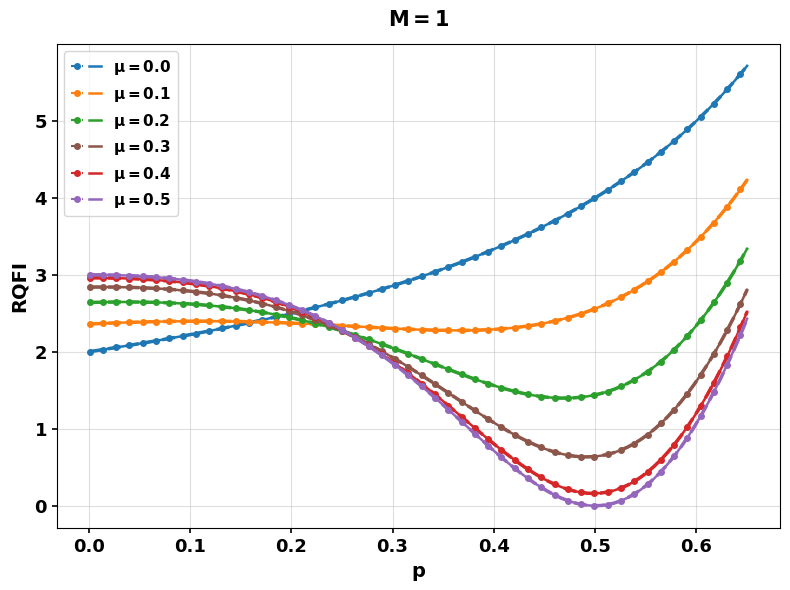

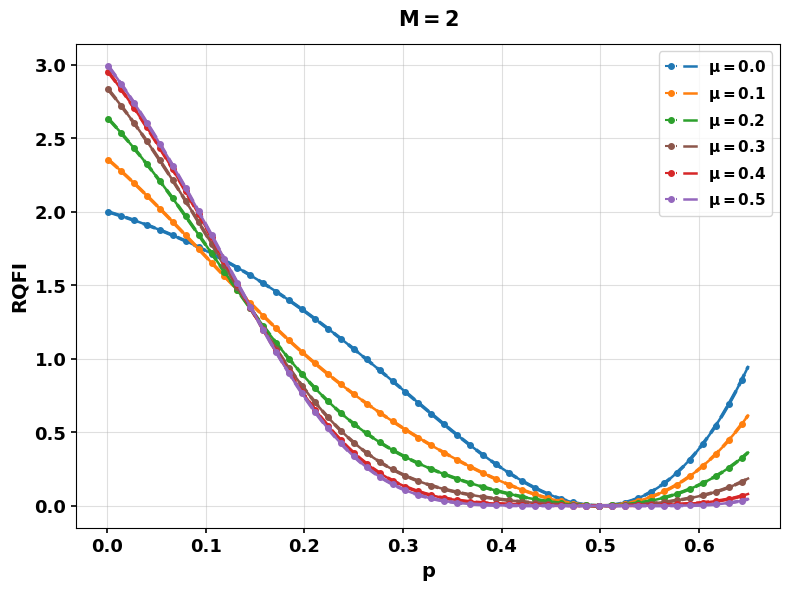

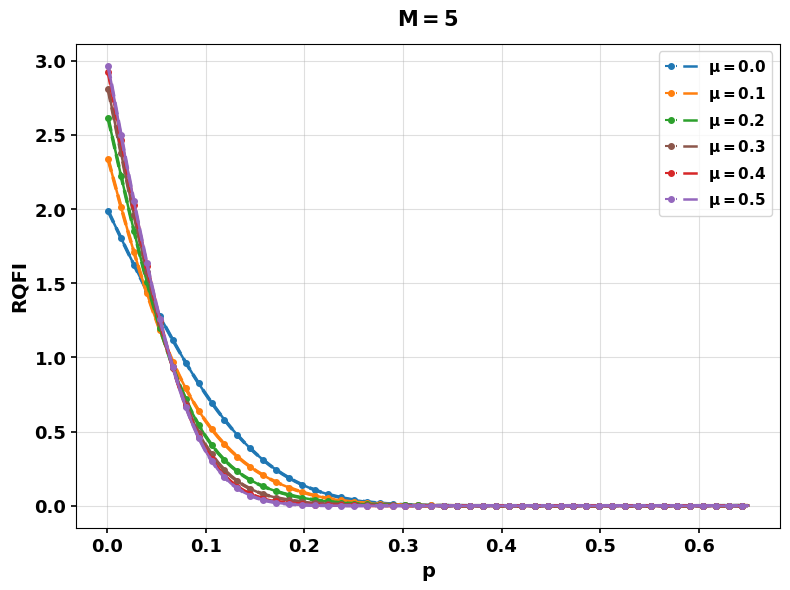

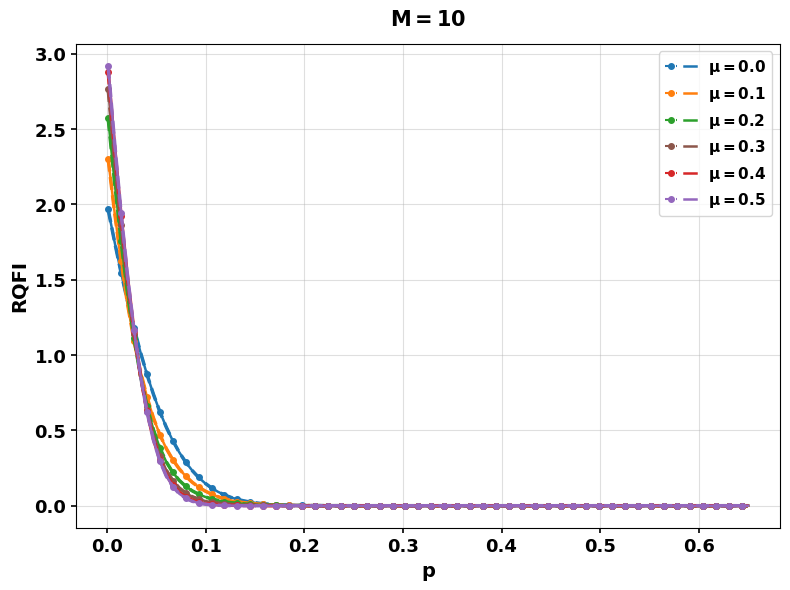

In [41]:
colors = ['tab:blue',
          'tab:orange',
          'tab:green',
          'tab:brown',
          'tab:red',
          'tab:purple']

labels = [fr'$\mathbf{{\mu={mu}}}$' for mu in mu_values]

for M in [1,2,5,10]:

    fig, ax = plt.subplots(figsize=(8,6))

    handles=[]

    for mu,col in zip(mu_values,colors):

        rho_init = create_initial_state(mu)
        S_init   = make_S(rho_init)

        qfi_num=[]
        qfi_ana=[]

        for eps in eps_range:

            rho_out = depolarizing_generic(rho_init,eps,M)
            drho    = d_Lambda_deps_generic(eps,rho_init,S_init,M)

            qfi_num.append(
                (eps*compute_qfi_numerical(rho_out,drho))/M
            )

            qfi_ana.append(
                (eps*compute_qfi_analytical_generic(mu,eps,M))/M
            )

        # Numerical
        ax.plot(
            eps_range,
            qfi_num,
            '--o',
            markevery=2,
            markersize=4,
            color=col,
            linewidth=2.5
        )

        # Analytical
        ax.plot(
            eps_range,
            qfi_ana,
            color=col,
            linewidth=1.8
        )

        handles.append(
            (
                Line2D([],[],
                       color=col,
                       linestyle='--',
                       marker='o',
                       markersize=4),

                Line2D([],[],
                       color=col,
                       linestyle='-',
                       linewidth=1.8)
            )
        )

    # --------------------------
    # Labels
    # --------------------------

    ax.set_xlabel(
        'p',
        fontsize=14,
        fontweight='bold'
    )

    ax.set_ylabel(
        'RQFI',
        fontsize=14,
        fontweight='bold'
    )

    # --------------------------
    # Tick labels
    # --------------------------

    ax.tick_params(
        axis='both',
        labelsize=13,
        width=1.2
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight('bold')

    for tick in ax.get_yticklabels():
        tick.set_fontweight('bold')

    # --------------------------
    # M label
    # --------------------------

    ax.text(
        0.50,
        1.03,
        fr'$\mathbf{{M={M}}}$',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=15
    )

    # --------------------------
    # Legend position
    # --------------------------

    if M == 1:
        legend_location = 'upper left'
    else:
        legend_location = 'upper right'

    ax.legend(
        handles,
        labels,
        handler_map={
            tuple: plt.matplotlib.legend_handler.HandlerTuple(ndivide=None)
        },
        loc=legend_location,
        frameon=True,
        prop={
            'weight':'bold',
            'size':11
        }
    )

    ax.grid(True,alpha=0.4)

    plt.tight_layout()

    plt.show()

## <span style="color:orange"><strong> *Figure 5* <strong></span>

### <span style="color:green"><strong> *Parameters* <strong></span>

In [43]:
M_values = range(1, 40)

p_values = np.array([
    0.03, 0.035, 0.04, 0.05,
    0.07, 0.10, 0.15, 0.30
])

mu_fixed = 0.2

# Same weighted GHZ initial state
rho_init = create_initial_state(mu_fixed)
S_init = make_S(rho_init)

### <span style="color:green"><strong> *Plotting* <strong></span>

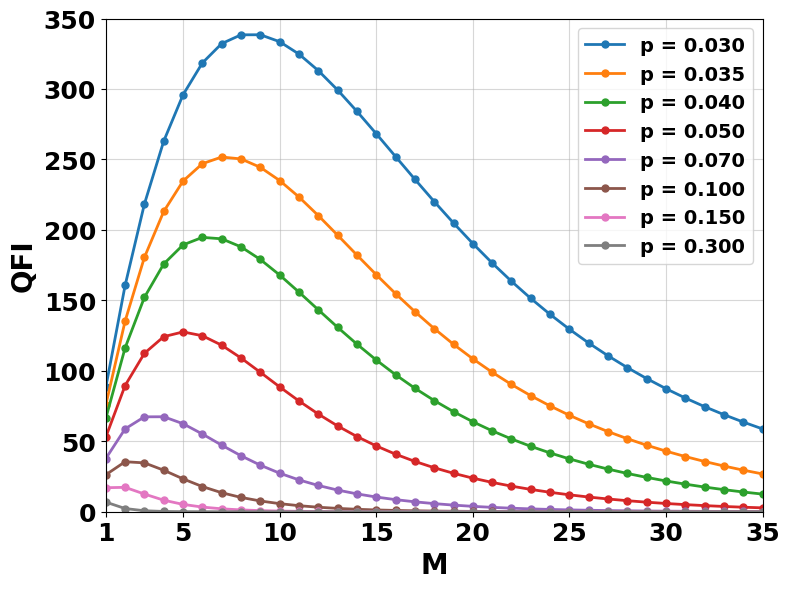

In [ ]:
plt.figure(figsize=(8, 6))


for p in p_values:

    qfi_vs_M = []

    for M in M_values:

        # Output state after M applications
        rho_out = depolarizing_generic(
            rho_init,
            p,
            M
        )

        # Exact analytical derivative dρ/dp
        drho_dp = d_Lambda_deps_generic(
            p,
            rho_init,
            S_init,
            M
        )

        # Numerical QFI through SLD
        qfi = compute_qfi_numerical(
            rho_out,
            drho_dp
        )

        qfi_vs_M.append(qfi)


    # Plot QFI vs M
    plt.plot(
        M_values,
        qfi_vs_M,
        'o-',
        linewidth=2,
        markersize=5,
        label=f'p = {p:.3f}'
    )


# ==============================
# Plot formatting
# ==============================

plt.xlabel(
    'M',
    fontsize=20,
    fontweight='bold'
)

plt.ylabel(
    'QFI',
    fontsize=20,
    fontweight='bold'
)

plt.xticks(
    [1, 5, 10, 15, 20, 25, 30, 35, 39],
    fontsize=18,
    fontweight='bold'
)

plt.yticks(
    fontsize=18,
    fontweight='bold'
)

plt.xlim(1, 35)
plt.ylim(0, 350)

plt.grid(
    True,
    alpha=0.5
)

plt.legend(
    fontsize=14,
    prop={
        'weight': 'bold',
        'size': 14
    }
)

plt.tight_layout()

plt.show()

## <span style="color:orange"><strong> *Figure 6-Best M* <strong></span>

### <span style="color:green"><strong> *Simulation parameters* <strong></span>

In [104]:
p_min = 0.01
p_max = 0.50
num_p_points = 100

p_vec = np.linspace(p_min, p_max, num_p_points)

M_vec = range(1, 100)

# Main plot mu values
mu_main = np.linspace(0, 0.5, 6)

# Heatmap mu values
mu_heatmap = np.linspace(0, 0.5, 20)

delta_p = 0.002

### <span style="color:green"><strong> *Function: Find Best M for given p and mu* <strong></span>

In [105]:
def find_best_M(mu, p):

    rho_initial = create_initial_state(mu)

    best_M = 1
    best_qfi = 0.0

    for M in M_vec:

        # rho(p)
        rho_current = depolarizing_generic(
            rho_initial,
            p,
            M
        )

        # rho(p + delta_p)
        rho_plus = depolarizing_generic(
            rho_initial,
            p + delta_p,
            M
        )

        # Numerical derivative
        drho_dp = (
            rho_plus - rho_current
        ) / delta_p

        # QFI
        qfi_value = compute_qfi_numerical(
            rho_current,
            drho_dp
        )

        # Keep M giving maximum QFI
        if qfi_value > best_qfi:

            best_qfi = qfi_value
            best_M = M

    return best_M, best_qfi

### <span style="color:green"><strong> *Main Plot Data: Best M vs p for mu = 0, 0.1, ..., 0.5* <strong></span>

In [106]:
main_results = []

for mu in mu_main:

    print(f"Calculating main curve for mu = {mu:.1f}")

    for p in p_vec:

        best_M, best_qfi = find_best_M(mu, p)

        main_results.append([
            mu,
            p,
            best_M,
            best_qfi
        ])


df_main = pd.DataFrame(
    main_results,
    columns=[
        "mu",
        "p",
        "best_M",
        "best_qfi"
    ]
)

Calculating main curve for mu = 0.0
Calculating main curve for mu = 0.1
Calculating main curve for mu = 0.2
Calculating main curve for mu = 0.3
Calculating main curve for mu = 0.4
Calculating main curve for mu = 0.5


### <span style="color:green"><strong> *Heatmap Data* <strong></span>

In [107]:
p_heatmap = p_vec[p_vec <= 0.15]

heatmap_results = []

for mu in mu_heatmap:

    print(f"Calculating heatmap for mu = {mu:.3f}")

    for p in p_heatmap:

        best_M, best_qfi = find_best_M(mu, p)

        heatmap_results.append([
            p,
            mu,
            best_M,
            best_qfi
        ])


df_heatmap = pd.DataFrame(
    heatmap_results,
    columns=[
        "p",
        "mu",
        "best_M",
        "best_qfi"
    ]
)

Calculating heatmap for mu = 0.000
Calculating heatmap for mu = 0.026
Calculating heatmap for mu = 0.053
Calculating heatmap for mu = 0.079
Calculating heatmap for mu = 0.105
Calculating heatmap for mu = 0.132
Calculating heatmap for mu = 0.158
Calculating heatmap for mu = 0.184
Calculating heatmap for mu = 0.211
Calculating heatmap for mu = 0.237
Calculating heatmap for mu = 0.263
Calculating heatmap for mu = 0.289
Calculating heatmap for mu = 0.316
Calculating heatmap for mu = 0.342
Calculating heatmap for mu = 0.368
Calculating heatmap for mu = 0.395
Calculating heatmap for mu = 0.421
Calculating heatmap for mu = 0.447
Calculating heatmap for mu = 0.474
Calculating heatmap for mu = 0.500


### <span style="color:green"><strong> *Prepare Heatmap* <strong></span>

In [108]:
heatmap_data = df_heatmap.pivot(
    index="mu",
    columns="p",
    values="best_M"
)

P = heatmap_data.columns.values
MU = heatmap_data.index.values
Z = heatmap_data.values

PP, MM = np.meshgrid(P, MU)

### <span style="color:green"><strong> *Plotting* <strong></span>

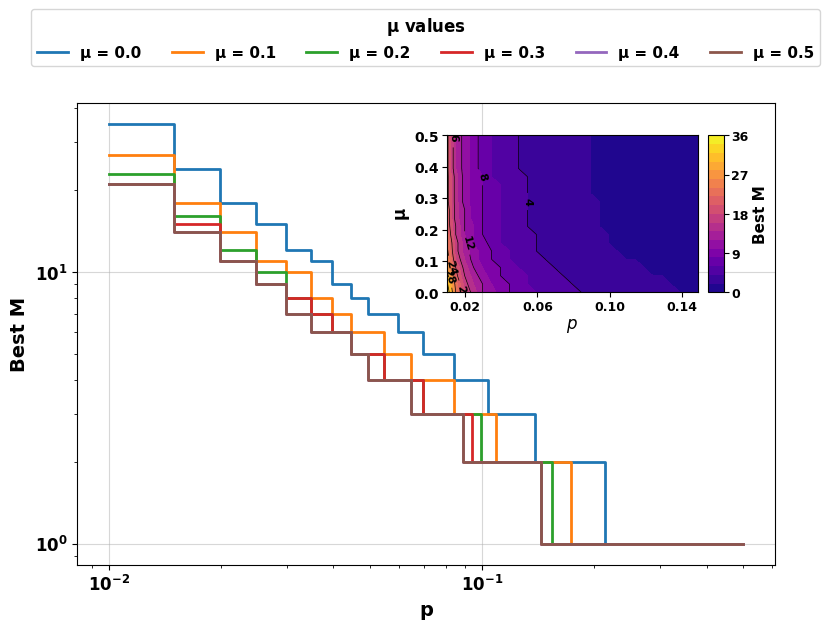

In [ ]:
# ============================================================
# Combined Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6.5)
)

# Space for horizontal legend
fig.subplots_adjust(top=0.82)


# ============================================================
# Main Plot
# ============================================================

for mu in mu_main:

    df_mu = df_main[
        np.isclose(df_main["mu"], mu)
    ]

    ax.step(
        df_mu["p"],
        df_mu["best_M"],
        where="post",
        linewidth=2,
        label=f'μ = {mu:.1f}'
    )


# ============================================================
# Main Axes Formatting
# ============================================================

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(
    "p",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Best M",
    fontsize=14,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=12
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

ax.grid(
    True,
    alpha=0.5
)


# ============================================================
# Legend
# ============================================================

legend = ax.legend(
    title=r"$\mathbf{\mu}$ values",
    fontsize=11,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.22),
    ncol=6,
    frameon=True,
    prop={
        "weight": "bold",
        "size": 11
    }
)

legend.get_title().set_fontweight("bold")
legend.get_title().set_fontsize(12)


# ============================================================
# Inset Heatmap (Values: left, bottom, width, height)
# ============================================================

axins = ax.inset_axes(
    [0.53, 0.59, 0.36, 0.34]
)

contour = axins.contourf(
    PP,
    MM,
    Z,
    levels=20,
    cmap="plasma"
)

lines = axins.contour(
    PP,
    MM,
    Z,
    levels=10,
    colors="black",
    linewidths=0.5
)

contour_labels = axins.clabel(
    lines,
    inline=True,
    fontsize=8,
    fmt="%.0f"
)

for txt in contour_labels:
    txt.set_fontweight("bold")


# ============================================================
# Inset Formatting
# ============================================================

axins.set_xlabel(
    r"$p$",
    fontsize=12,
    fontweight="bold",
    labelpad=2
)

axins.set_ylabel(
    r"$\mathbf{\mu}$",
    fontsize=12,
    fontweight="bold",
    labelpad=2
)

axins.tick_params(
    axis="both",
    labelsize=10,
    pad=2
)

# Clean p-axis ticks
axins.set_xticks([0.02, 0.06, 0.10, 0.14])

axins.set_xticklabels(
    ["0.02", "0.06", "0.10", "0.14"],
    fontsize=9,
    fontweight="bold"
)

for label in axins.get_yticklabels():
    label.set_fontweight("bold")


# ============================================================
# Inset Colorbar
# ============================================================

cbar_ax = ax.inset_axes(
    [0.905, 0.59, 0.022, 0.34]
)

cbar = fig.colorbar(
    contour,
    cax=cbar_ax
)

# Best-M ticks
cbar.set_ticks([0, 9, 18, 27, 36])

cbar.set_label(
    "Best M",
    fontsize=11,
    fontweight="bold",
    labelpad=3
)

cbar.ax.tick_params(
    labelsize=9,
    pad=2
)

for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")


# ============================================================
# Final Figure
# ============================================================


plt.show()

## <span style="color:orange"><strong> *Figure 7 - Best $\mu$* <strong></span>

In [200]:
p_maxx = 0.6
p_minn = 0.001

In [201]:
outcome_Full_Range = []

M_vec = range(1, 100)

num_p_points_high = 400
num_mu_points_high = 501

p_vec = np.linspace(p_minn, p_maxx, num_p_points_high, True)
mu_vec = np.linspace(0, 0.5, num_mu_points_high, True)

delta_p = (p_maxx - p_minn) / (num_p_points_high - 1)

for p in p_vec:
    for M in M_vec:

        best_mu = 0
        best_qfi = 0

        for mu in mu_vec:

            rho_initial = create_initial_state(mu)

            rho_current = depolarizing_generic(rho_initial, p, M)

            rho_plus = depolarizing_generic(rho_initial, p + delta_p, M)

            drho_dp = (rho_plus - rho_current) / delta_p

            qfi_value = compute_qfi_numerical(rho_current, drho_dp)

            if qfi_value > best_qfi:
                best_qfi = qfi_value
                best_mu = mu

        outcome_Full_Range.append([p, M, best_mu, best_qfi])

In [202]:
df_muFull_Range = pd.DataFrame(outcome_Full_Range, columns=["p", "M", "best_mu", "best_qfi"])

display(df_muFull_Range)

,p,M,best_mu,best_qfi
0,0.001,1,0.5,2.990975e+03
1,0.001,2,0.5,5.928197e+03
2,0.001,3,0.5,8.812405e+03
3,0.001,4,0.5,1.164433e+04
4,0.001,5,0.5,1.442469e+04
...,...,...,...,...
39595,0.600,95,0.5,5.570392e-258
39596,0.600,96,0.5,9.494833e-261
39597,0.600,97,0.5,1.618226e-263
39598,0.600,98,0.5,2.757675e-266


### <span style="color:green"><strong> *Plotting* <strong></span>

### <span style="color:green"><strong> *Cutoff Check* <strong></span>

QFI cutoff = 1e-04
Points below cutoff = 30691/39600 (77.50%)


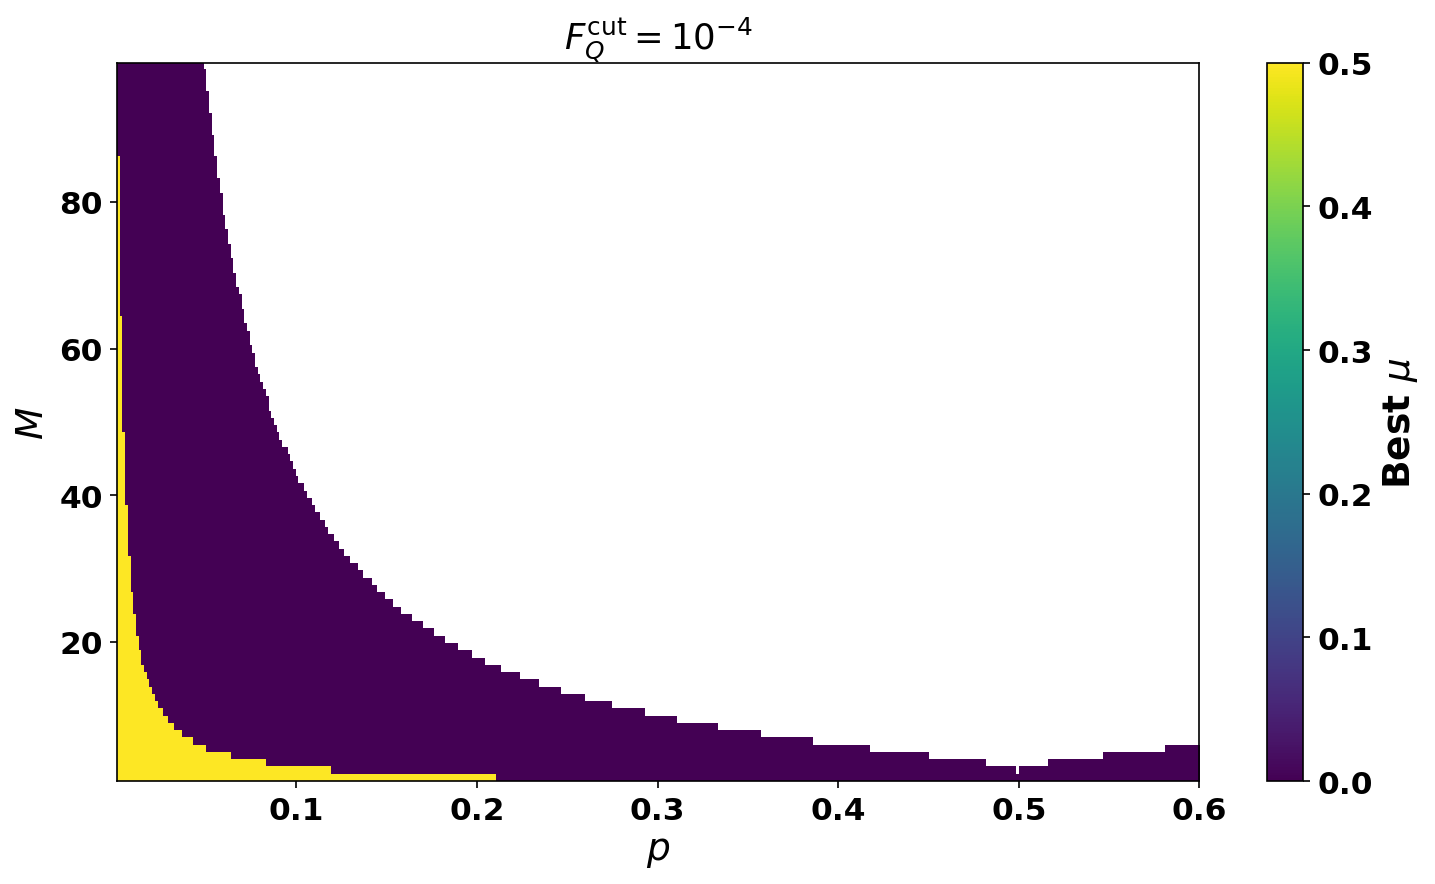

In [ ]:
# ============================================================
# QFI CUTOFF ON THE FULL EXISTING DATA
# p = 0.001 to 0.6
# M = 1 to 99
# ============================================================


# ------------------------------------------------------------
# 1. Choose QFI cutoff
# ------------------------------------------------------------

qfi_cutoff = 1e-4


# ------------------------------------------------------------
# 2. Make a copy of the already calculated data given above
# ------------------------------------------------------------

df_cutoff = df_muFull_Range.copy()


# ------------------------------------------------------------
# 3. Check how many points are below the cutoff
# ------------------------------------------------------------

removed_points = (
    df_cutoff["best_qfi"] < qfi_cutoff
).sum()

total_points = len(df_cutoff)

removed_percentage = (
    100 * removed_points / total_points
)

print(f"QFI cutoff = {qfi_cutoff:.0e}")
print(
    f"Points below cutoff = {removed_points}/{total_points} "
    f"({removed_percentage:.2f}%)"
)


# ------------------------------------------------------------
# 4. Mask Best-mu where QFI is below the cutoff
# ------------------------------------------------------------

df_cutoff.loc[
    df_cutoff["best_qfi"] < qfi_cutoff,
    "best_mu"
] = np.nan


# ------------------------------------------------------------
# 5. Prepare heatmap
# ------------------------------------------------------------

heatmap_data_mu = df_cutoff.pivot(
    index="M",
    columns="p",
    values="best_mu"
)


# ------------------------------------------------------------
# 6. Colormap
# White = QFI below cutoff
# ------------------------------------------------------------

cmap = plt.cm.viridis.copy()
cmap.set_bad(color="white")


# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6), dpi=150)

im_mu = plt.imshow(
    heatmap_data_mu.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmap,
    vmin=0,
    vmax=0.5,
    extent=[
        heatmap_data_mu.columns.min(),
        heatmap_data_mu.columns.max(),
        heatmap_data_mu.index.min(),
        heatmap_data_mu.index.max()
    ]
)


# ------------------------------------------------------------
# 8. Colorbar
# ------------------------------------------------------------

cbar = plt.colorbar(im_mu)

cbar.set_label(
    r"Best $\mu$",
    fontsize=18,
    fontweight="bold"
)

cbar.ax.tick_params(labelsize=15)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight("bold")


# ------------------------------------------------------------
# 9. Axes
# ------------------------------------------------------------

plt.xlabel(
    r"$p$",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    r"$M$",
    fontsize=18,
    fontweight="bold"
)

plt.xticks(fontsize=15, fontweight="bold")
plt.yticks(fontsize=15, fontweight="bold")


# ------------------------------------------------------------
# 10. Title
# ------------------------------------------------------------

plt.title(
    rf"$F_Q^{{\mathrm{{cut}}}} = 10^{{{int(np.log10(qfi_cutoff))}}}$",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## <span style="color:orange"><strong> *Figure 8* <strong></span>

### <span style="color:green"><strong> *Numerical RQFI* <strong></span>

In [ ]:
# =========================================================
# 1. Numerical RQFI 
# =========================================================

def compute_rqfi_numerical(rho_initial, p, M, h_qfi=1e-8):
    """
    Numerical Regularized QFI:

        RQFI = (p * QFI) / M

    Here drho/dp is calculated numerically.
    h_qfi is used only for calculating drho/dp.
    """

    rho_current = depolarizing_generic(rho_initial, p, M)

    # Use central difference if possible
    if p - h_qfi > 0:

        rho_plus = depolarizing_generic(
            rho_initial,
            p + h_qfi,
            M
        )

        rho_minus = depolarizing_generic(
            rho_initial,
            p - h_qfi,
            M
        )

        drho_dp = (
            rho_plus - rho_minus
        ) / (2 * h_qfi)

    else:

        rho_plus = depolarizing_generic(
            rho_initial,
            p + h_qfi,
            M
        )

        drho_dp = (
            rho_plus - rho_current
        ) / h_qfi

    qfi = compute_qfi_numerical(
        rho_current,
        drho_dp
    )

    rqfi = (p * qfi) / M

    return np.real_if_close(rqfi)


def numerical_slope_near_zero(
    rho_initial,
    M,
    p0=1e-5,
    h_slope=1e-5,
    h_qfi=1e-8
):
    """
    Numerical slope of RQFI near p = 0:

        slope ≈ [RQFI(p0 + h_slope) - RQFI(p0)] / h_slope
    """

    rqfi_p0 = compute_rqfi_numerical(
        rho_initial,
        p0,
        M,
        h_qfi=h_qfi
    )

    rqfi_p1 = compute_rqfi_numerical(
        rho_initial,
        p0 + h_slope,
        M,
        h_qfi=h_qfi
    )

    slope = (
        rqfi_p1 - rqfi_p0
    ) / h_slope

    return np.real_if_close(slope)

### <span style="color:green"><strong> *Analytical RQFI* <strong></span>

In [134]:
# =========================================================
# 2. Analytical RQFI from closed-form formula
# =========================================================

def Acoef(p, M):
    return (1 - 2*p)**(2*M)


def Fcoef(p, M):
    return (
        1
        - 2*(1 - 2*p)**M
        + Acoef(p, M)
    ) / 4


def r_mu(mu):
    return np.sqrt(mu*(1 - mu))


def alpha_coef(p, M):
    return -4*M*(1 - 2*p)**(2*M - 1)


def d00_analytical(p, M, mu):
    return (
        M
        * (1 - 2*p)**(M - 1)
        * ((1 - 2*mu) - (1 - 2*p)**M)
    )


def d33_analytical(p, M, mu):
    return (
        M
        * (1 - 2*p)**(M - 1)
        * ((2*mu - 1) - (1 - 2*p)**M)
    )


def d03_analytical(p, M, mu):
    return alpha_coef(p, M) * r_mu(mu)


def d11_analytical(p, M):
    return M*(1 - 2*p)**(2*M - 1)


def m00_analytical(p, M, mu):
    return (
        mu*(1 - 2*p)**M
        + Fcoef(p, M)
    )


def m11_analytical(p, M, mu):
    return (
        (1 - mu)*(1 - 2*p)**M
        + Fcoef(p, M)
    )


def m01_analytical(p, M, mu):
    return (
        (1 - 2*p)**(2*M)
        * r_mu(mu)
    )


def m_analytical(p, M, mu):
    return (
        m00_analytical(p, M, mu)
        + m11_analytical(p, M, mu)
    ) / 2


def R_analytical(p, M, mu):
    return np.sqrt(

        (
            (
                m00_analytical(p, M, mu)
                - m11_analytical(p, M, mu)
            ) / 2
        )**2

        +

        m01_analytical(p, M, mu)**2
    )


def lambdaplus_analytical(p, M, mu):
    return (
        m_analytical(p, M, mu)
        + R_analytical(p, M, mu)
    )


def lambdaminus_analytical(p, M, mu):
    return (
        m_analytical(p, M, mu)
        - R_analytical(p, M, mu)
    )


def lambdab_analytical(p, M):
    return (
        1
        - (1 - 2*p)**(2*M)
    ) / 4


def cos2theta_analytical(p, M, mu):

    R = R_analytical(p, M, mu)

    return (
        (2*mu - 1)
        * (1 - 2*p)**M
    ) / (2*R)


def c_analytical(p, M, mu):

    val = (
        1
        + cos2theta_analytical(p, M, mu)
    ) / 2

    # This avoids tiny negative values due to numerical roundoff
    return np.sqrt(
        np.maximum(val, 0)
    )


def s_analytical(p, M, mu):

    val = (
        1
        - cos2theta_analytical(p, M, mu)
    ) / 2

    return np.sqrt(
        np.maximum(val, 0)
    )


def dplusplus_analytical(p, M, mu):

    c = c_analytical(p, M, mu)
    s = s_analytical(p, M, mu)

    return (
        c**2*d00_analytical(p, M, mu)
        + s**2*d33_analytical(p, M, mu)
        + 2*c*s*d03_analytical(p, M, mu)
    )


def dminusminus_analytical(p, M, mu):

    c = c_analytical(p, M, mu)
    s = s_analytical(p, M, mu)

    return (
        s**2*d00_analytical(p, M, mu)
        + c**2*d33_analytical(p, M, mu)
        - 2*c*s*d03_analytical(p, M, mu)
    )


def dplusminus_analytical(p, M, mu):

    c = c_analytical(p, M, mu)
    s = s_analytical(p, M, mu)

    return (
        (c**2 - s**2)
        * d03_analytical(p, M, mu)

        - c*s*(
            d00_analytical(p, M, mu)
            - d33_analytical(p, M, mu)
        )
    )


def FQ_analytical(p, M, mu):

    lp = lambdaplus_analytical(
        p, M, mu
    )

    lm = lambdaminus_analytical(
        p, M, mu
    )

    lb = lambdab_analytical(
        p, M
    )

    FQ1 = (
        dplusplus_analytical(p, M, mu)**2
        / lp
    )

    FQ2 = (
        dminusminus_analytical(p, M, mu)**2
        / lm
    )

    FQ3 = (
        4*dplusminus_analytical(p, M, mu)**2
        / (lp + lm)
    )

    FQ4 = (
        2*d11_analytical(p, M)**2
        / lb
    )

    return FQ1 + FQ2 + FQ3 + FQ4


def RQFI_analytical(p, M, mu):
    """
    Analytical regularized QFI:

        RQFI = (p * FQ) / M
    """

    rqfi = (
        p
        * FQ_analytical(p, M, mu)
    ) / M

    return np.real_if_close(rqfi)


def analytical_slope_near_zero(
    M,
    mu,
    p0=1e-5,
    h_slope=1e-5
):
    """
    Analytical slope near p = 0 using same finite-difference style
    as numerical code:

        slope ≈ [RQFI(p0 + h_slope) - RQFI(p0)] / h_slope
    """

    rqfi_p0 = RQFI_analytical(
        p0,
        M,
        mu
    )

    rqfi_p1 = RQFI_analytical(
        p0 + h_slope,
        M,
        mu
    )

    slope = (
        rqfi_p1 - rqfi_p0
    ) / h_slope

    return np.real_if_close(slope)

### <span style="color:green"><strong> *Parameters* <strong></span>

In [135]:
M_values_slope = [
    1,
    2,
    3
]

p0 = 1e-5
h_slope = 1e-5
h_qfi = 1e-8

### <span style="color:green"><strong> *Plotting* <strong></span>

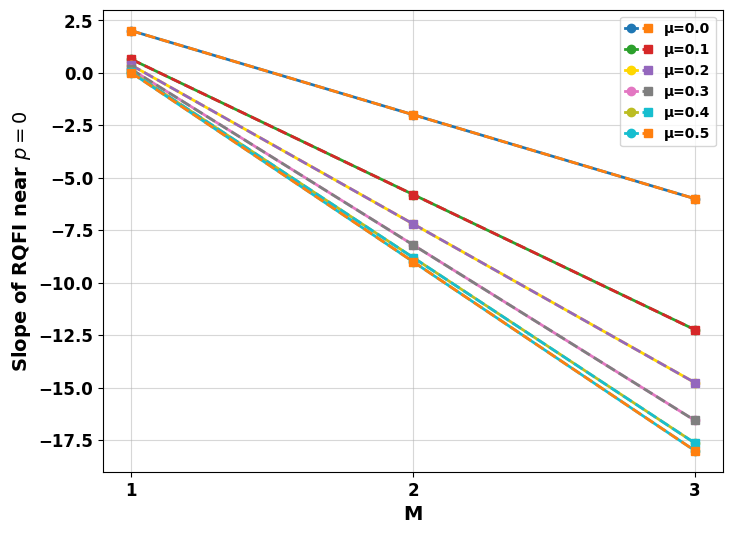

In [ ]:
# =========================================================
# 5. Plot numerical vs analytical slope
# =========================================================

plt.figure(figsize=(8, 6))


# Colors chosen to match previous figures
num_colors = [
    'tab:blue',
    'tab:green',
    'gold',
    'tab:pink',
    'tab:olive',
    'tab:cyan'
]

ana_colors = [
    'tab:orange',
    'tab:red',
    'tab:purple',
    'tab:gray',
    'tab:cyan',
    'tab:orange'
]


handles = []

labels = [
    f'μ={mu:.1f}'
    for mu in mu_values
]


for mu, num_col, ana_col in zip(
    mu_values,
    num_colors,
    ana_colors
):

    rho_initial = create_initial_state(mu)

    numerical_slopes = []
    analytical_slopes = []


    for M in M_values_slope:

        slope_num = numerical_slope_near_zero(
            rho_initial,
            M,
            p0=p0,
            h_slope=h_slope,
            h_qfi=h_qfi
        )

        slope_ana = analytical_slope_near_zero(
            M,
            mu,
            p0=p0,
            h_slope=h_slope
        )


        numerical_slopes.append(
            np.real_if_close(
                slope_num
            ).item()
        )

        analytical_slopes.append(
            np.real_if_close(
                slope_ana
            ).item()
        )


    # -------------------------
    # Numerical
    # -------------------------

    plt.plot(
        M_values_slope,
        numerical_slopes,
        'o-',
        color=num_col,
        linewidth=2,
        markersize=6
    )


    # -------------------------
    # Analytical
    # -------------------------

    plt.plot(
        M_values_slope,
        analytical_slopes,
        's--',
        color=ana_col,
        linewidth=2,
        markersize=6
    )


    # -------------------------
    # One legend entry for each μ
    # -------------------------

    handles.append(
        (
            Line2D(
                [],
                [],
                color=num_col,
                linestyle='-',
                marker='o',
                linewidth=2,
                markersize=6
            ),

            Line2D(
                [],
                [],
                color=ana_col,
                linestyle='--',
                marker='s',
                linewidth=2,
                markersize=6
            )
        )
    )


# =========================================================
# Axis labels
# =========================================================

plt.xlabel(
    'M',
    fontsize=14,
    fontweight='bold'
)

plt.ylabel(
    r'Slope of RQFI near $p=0$',
    fontsize=14,
    fontweight='bold'
)


# =========================================================
# Axis ticks
# =========================================================

plt.xticks(
    M_values,
    fontsize=12,
    fontweight='bold'
)

plt.yticks(
    fontsize=12,
    fontweight='bold'
)


# =========================================================
# Legend
# =========================================================

plt.legend(
    handles,
    labels,

    handler_map={
        tuple:
        plt.matplotlib.legend_handler.HandlerTuple(
            ndivide=None
        )
    },

    loc='best',

    ncol=1,

    prop={
        'weight': 'bold',
        'size': 10
    }
)


# =========================================================
# Grid
# =========================================================

plt.grid(
    True,
    alpha=0.5
)

plt.show()

## <span style="color:orange"><strong> *Figure 9* <strong></span>

In [137]:
M_values_Slope = [1, 2, 3, 4, 5, 6]

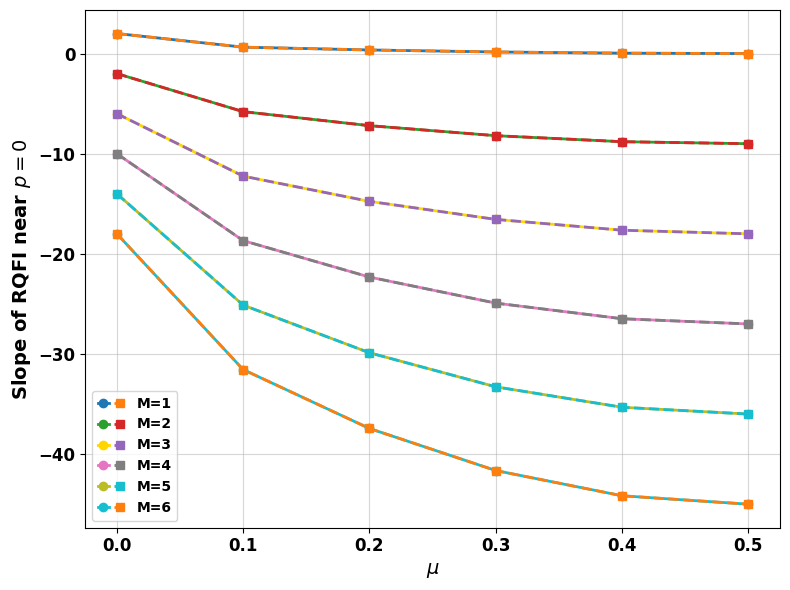

In [138]:
# =========================================================
# 5. Plot numerical vs analytical slope
#     Slope vs μ for different M
# =========================================================

plt.figure(figsize=(8,6))

# Numerical colors
num_colors = [
    'tab:blue',
    'tab:green',
    'gold',
    'tab:pink',
    'tab:olive',
    'tab:cyan'
]

# Analytical colors
ana_colors = [
    'tab:orange',
    'tab:red',
    'tab:purple',
    'tab:gray',
    'tab:cyan',
    'tab:orange'
]

handles = []
labels = [f'M={M}' for M in M_values_Slope]

for M, num_col, ana_col in zip(M_values_Slope, num_colors, ana_colors):

    numerical_slopes = []
    analytical_slopes = []

    for mu in mu_values:

        rho_initial = create_initial_state(mu)

        slope_num = numerical_slope_near_zero(
            rho_initial,
            M,
            p0=p0,
            h_slope=h_slope,
            h_qfi=h_qfi
        )

        slope_ana = analytical_slope_near_zero(
            M,
            mu,
            p0=p0,
            h_slope=h_slope
        )

        numerical_slopes.append(
            np.real_if_close(slope_num).item()
        )

        analytical_slopes.append(
            np.real_if_close(slope_ana).item()
        )

    # -------------------------
    # Numerical
    # -------------------------
    plt.plot(
        mu_values,
        numerical_slopes,
        'o-',
        color=num_col,
        linewidth=2,
        markersize=6
    )

    # -------------------------
    # Analytical
    # -------------------------
    plt.plot(
        mu_values,
        analytical_slopes,
        's--',
        color=ana_col,
        linewidth=2,
        markersize=6
    )

    # -------------------------
    # One legend entry
    # -------------------------
    handles.append(
        (
            Line2D(
                [],
                [],
                color=num_col,
                linestyle='-',
                marker='o',
                linewidth=2,
                markersize=6
            ),
            Line2D(
                [],
                [],
                color=ana_col,
                linestyle='--',
                marker='s',
                linewidth=2,
                markersize=6
            )
        )
    )

plt.xlabel(
    r'$\mu$',
    fontsize=14,
    fontweight='bold'
)

plt.ylabel(
    r'Slope of RQFI near $p=0$',
    fontsize=14,
    fontweight='bold'
)

plt.xticks(
    mu_values,
    fontsize=12,
    fontweight='bold'
)

plt.yticks(
    fontsize=12,
    fontweight='bold'
)

plt.legend(
    handles,
    labels,
    handler_map={
        tuple: plt.matplotlib.legend_handler.HandlerTuple(ndivide=None)
    },
    loc='best',
    ncol=1,
    prop={
        'weight':'bold',
        'size':10
    }
)

plt.grid(True, alpha=0.5)

plt.tight_layout()

plt.show()

## <span style="color:orange"><strong> *Figure 10* <strong></span>

### <span style="color:green"><strong> *Our analytical QFI (Generic M)* <strong></span>

In [145]:
def qfi_qubit(p, M):

    p_paper = (1 - 2*p)**M

    numerator = (
        4 * M**2 * (1 - 2*p)**(2*M - 2)
    )

    denominator = (
        (1 + p_paper) * (1 - p_paper)
    )

    return numerator / denominator

### <span style="color:green"><strong> *Fujiwara best-strategy QFI* <strong></span>


In [146]:
def fujiwara_best_qfi_p(p):

    p = np.asarray(p, dtype=float)
    theta = 1 - 2*p

    J_theta = np.full_like(theta, np.nan, dtype=float)

    theta_transition_1 = 1 / np.sqrt(3)
    theta_transition_2 = 1 / 3

    # --------------------------------------------------------
    # Region 1:
    # 1/sqrt(3) <= theta <= 1
    # Gamma_theta tensor Gamma_theta, mu = 1/2
    # J_theta = 12*theta^2 / [(1-theta^2)(1+3*theta^2)]
    # --------------------------------------------------------
    region_1 = (
        (theta >= theta_transition_1)
        & (theta <= 1)
    )

    J_theta[region_1] = (
        12 * theta[region_1]**2
    ) / (
        (1 - theta[region_1]**2)
        * (1 + 3*theta[region_1]**2)
    )

    # --------------------------------------------------------
    # Region 2:
    # 1/3 <= theta < 1/sqrt(3)
    # Two independent uses
    # J_theta = 2 / (1-theta^2)
    # --------------------------------------------------------
    region_2 = (
        (theta >= theta_transition_2)
        & (theta < theta_transition_1)
    )

    J_theta[region_2] = (
        2
        / (1 - theta[region_2]**2)
    )

    # --------------------------------------------------------
    # Region 3:
    # -1/3 <= theta < 1/3
    # Gamma_theta tensor I, mu = 1/2
    # J_theta = 3 / [(1-theta)(1+3*theta)]
    # --------------------------------------------------------
    region_3 = (
        (theta >= -1/3)
        & (theta < theta_transition_2)
    )

    J_theta[region_3] = (
        3
        / (
            (1 - theta[region_3])
            * (1 + 3*theta[region_3])
        )
    )

    # Convert from theta to p
    J_p = 4 * J_theta

    return J_p


### <span style="color:green"><strong> *Fixed Parameters* <strong></span>

In [147]:
p_range_Fujiwara = np.linspace(0.01, 0.5, 300)

M_values_Fujiwara = [10, 4, 2, 1]

colors = ['tab:blue', 'tab:orange', 'tab:red', 'tab:green']
markers = ['o', 's', 'o', 'o']

### <span style="color:green"><strong> *Transition points in p* <strong></span>

In [148]:
p_transition_1 = (1 - 1/np.sqrt(3)) / 2
p_transition_2 = 1/3

### <span style="color:green"><strong> *Plotting* <strong></span>

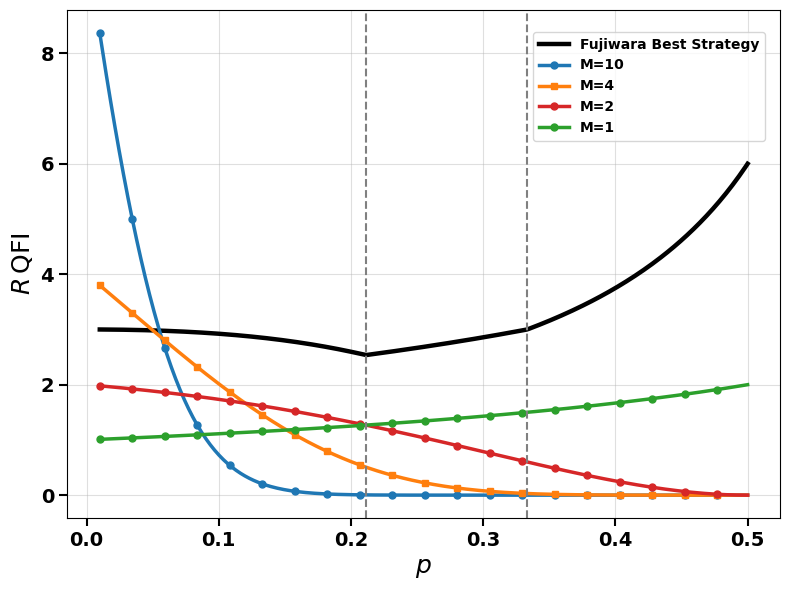

In [149]:
# ============================================================
# 5. Plot Regularized QFI
# ============================================================
plt.figure(figsize=(8, 6))


# ------------------------------------------------------------
# Fujiwara best-strategy regularized QFI
# p * J_p
# ------------------------------------------------------------
qfi_fujiwara = p_range_Fujiwara * fujiwara_best_qfi_p(p_range_Fujiwara)

plt.plot(
    p_range_Fujiwara,
    qfi_fujiwara,
    color='black',
    linewidth=3.2,
    label='Fujiwara Best Strategy'
)


# ------------------------------------------------------------
# Our regularized analytical QFI
# p * F_p^(M)
# ------------------------------------------------------------
for M, col, mk in zip(M_values, colors, markers):

    qfi_values = p_range_Fujiwara * qfi_qubit(p_range_Fujiwara, M)

    plt.plot(
        p_range_Fujiwara,
        qfi_values,
        color=col,
        linewidth=2.5,
        marker=mk,
        markevery=15,
        markersize=5,
        markerfacecolor=col,
        markeredgecolor=col,
        label=f'M={M}'
    )


# ============================================================
# 6. Fujiwara transition points
# ============================================================
plt.axvline(
    x=p_transition_1,
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.axvline(
    x=p_transition_2,
    color='gray',
    linestyle='--',
    linewidth=1.5
)


# ============================================================
# 7. Figure formatting
# ============================================================
plt.xlabel(
    r'$p$',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    r'$R\,\mathrm{QFI}$',
    fontsize=18,
    fontweight='bold'
)
plt.xticks(
    fontsize=14,
    fontweight='bold'
)

plt.yticks(
    fontsize=14,
    fontweight='bold'
)

plt.tick_params(
    axis='both',
    which='both',
    width=1.5,
    length=6
)

plt.legend(
    loc='upper right',
    bbox_to_anchor=(0.985, 0.965),
    prop={'weight': 'bold', 'size': 10},
    handlelength=2.2,
    borderaxespad=0.3
)
plt.grid(
    True,
    alpha=0.4
)

plt.tight_layout()

plt.show()